In [5]:
### my stuff ###
import sys
sys.path.append('..')
from consts import *
from functions import *

### python stuff ###
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as tk
from scipy.optimize import curve_fit
import scipy.misc as misc
import scipy.special as sp
from scipy import integrate
from scipy.interpolate import interp1d

In [6]:
pf = 10
mev = 10**6
kev = 10**3
M_Ar = 40*amu/mev # now in MeV

In [30]:
def cs_func(T, Mn, Ev): #all arguments in MeV
    return (2 - Mn * T / Ev**2) * 0.5

def getMax(Mn, Ev): #takes in MeV, returns a value in MeV
    return 2*Ev**2/Mn

neutrinos = [5, 7.5, 10] #in MeV

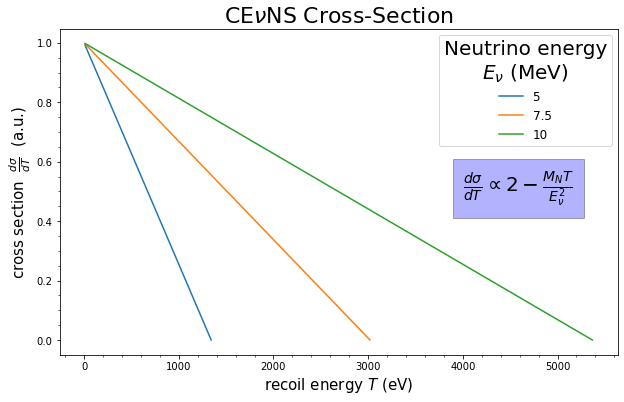

In [38]:
######### Quick plotter #########


# for E in neutrinos:
#     label = str(h)
#     ax.plot(widths, 180/pi*allowedAngle(widths, h) , label = "h = " + label + "mm")

fig, ax = plt.subplots(figsize = (10, 6))

for nu in neutrinos:
    Tmax = getMax(Mn = M_Ar, Ev = nu)
    Tlist = np.linspace(10/mev, Tmax, 100) #from 10 eV to Tmax
    ax.plot(Tlist*mev, cs_func(T = Tlist, Mn = M_Ar, Ev = nu), label = nu)

plt.ylabel(r"cross section  $\frac{d\sigma}{dT}$  (a.u.)", size = 15)
plt.xlabel(r"recoil energy $T$ (eV)", size = 15)
plt.title(r"CE$\nu$NS Cross-Section", size = 22)

plt.minorticks_on()
# plt.grid(b = True, which ='minor', axis ='x', linestyle = '--', markevery = '100')

#locmin = tk.LogLocator(base=10.0,subs=(0.2,0.4,0.6,0.8),numticks=12)
# ax.xaxis.set_minor_locator(locmin)
# ax.xaxis.set_minor_formatter(tk.NullFormatter())

# ax.set_xscale('log')
# plt.xlim(20, 25)
# plt.grid(True)

leg = plt.legend(prop={'size': 12}, title = "Neutrino energy\n" r"$E_\nu$ (MeV)")
plt.setp(leg.get_title(), multialignment='center')
leg.get_title().set_fontsize('20')

xs_text = r"$\frac{d\sigma}{dT} \propto 2 - \frac{M_NT}{E_\nu^2}$"
ax.text(4000, 0.5, xs_text, size = 20, bbox={'facecolor': 'blue', 'alpha': 0.3, 'pad': 10})

plt.savefig("cevns.png")
plt.show()